In [3]:
!pip -q install timm segmentation-models-pytorch fastai

from fastai.vision.all import *
from pathlib import Path
import segmentation_models_pytorch as smp
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)


/bin/bash: /home/exsdatalab/miniconda3/lib/libtinfo.so.6: no version information available (required by /bin/bash)
bash: /home/exsdatalab/miniconda3/lib/libtinfo.so.6: no version information available (required by bash)
bash: /home/exsdatalab/miniconda3/lib/libtinfo.so.6: no version information available (required by bash)
bash: /home/exsdatalab/miniconda3/lib/libtinfo.so.6: no version information available (required by bash)
bash: /home/exsdatalab/miniconda3/lib/libtinfo.so.6: no version information available (required by bash)
bash: /home/exsdatalab/miniconda3/lib/libtinfo.so.6: no version information available (required by bash)
bash: /home/exsdatalab/miniconda3/lib/libtinfo.so.6: no version information available (required by bash)
bash: /home/exsdatalab/miniconda3/lib/libtinfo.so.6: no version information available (required by bash)
bash: /home/exsdatalab/miniconda3/lib/libtinfo.so.6: no version information available (required by bash)
bash: /home/exsdatalab/miniconda3/lib/libtinf

In [4]:

DATA_ROOT = Path("dataset")     
IMAGES_DIR = DATA_ROOT/'images'
MASKS_DIR  = DATA_ROOT/'masks'  

print("Images dir:", IMAGES_DIR.resolve())
print("Masks  dir:", MASKS_DIR.resolve())

# quick sanity
images = get_image_files(IMAGES_DIR)
labels = get_image_files(MASKS_DIR)
print(f"Found {len(images)} images, {len(labels)} masks")
assert len(images) > 0, "No images found — check IMAGES_DIR"
assert len(labels) > 0, "No masks found — check MASKS_DIR"
images[:3], labels[:3]


Images dir: /home/exsdatalab/mlworks/mahmood_works/dataset/images
Masks  dir: /home/exsdatalab/mlworks/mahmood_works/dataset/masks
Found 2596 images, 2596 masks


((#3) [Path('dataset/images/001708.png'),Path('dataset/images/000050.png'),Path('dataset/images/001381.png')],
 (#3) [Path('dataset/masks/001708.png'),Path('dataset/masks/000050.png'),Path('dataset/masks/001381.png')])

In [5]:
im = images[2400]; im

Path('dataset/images/000722.png')

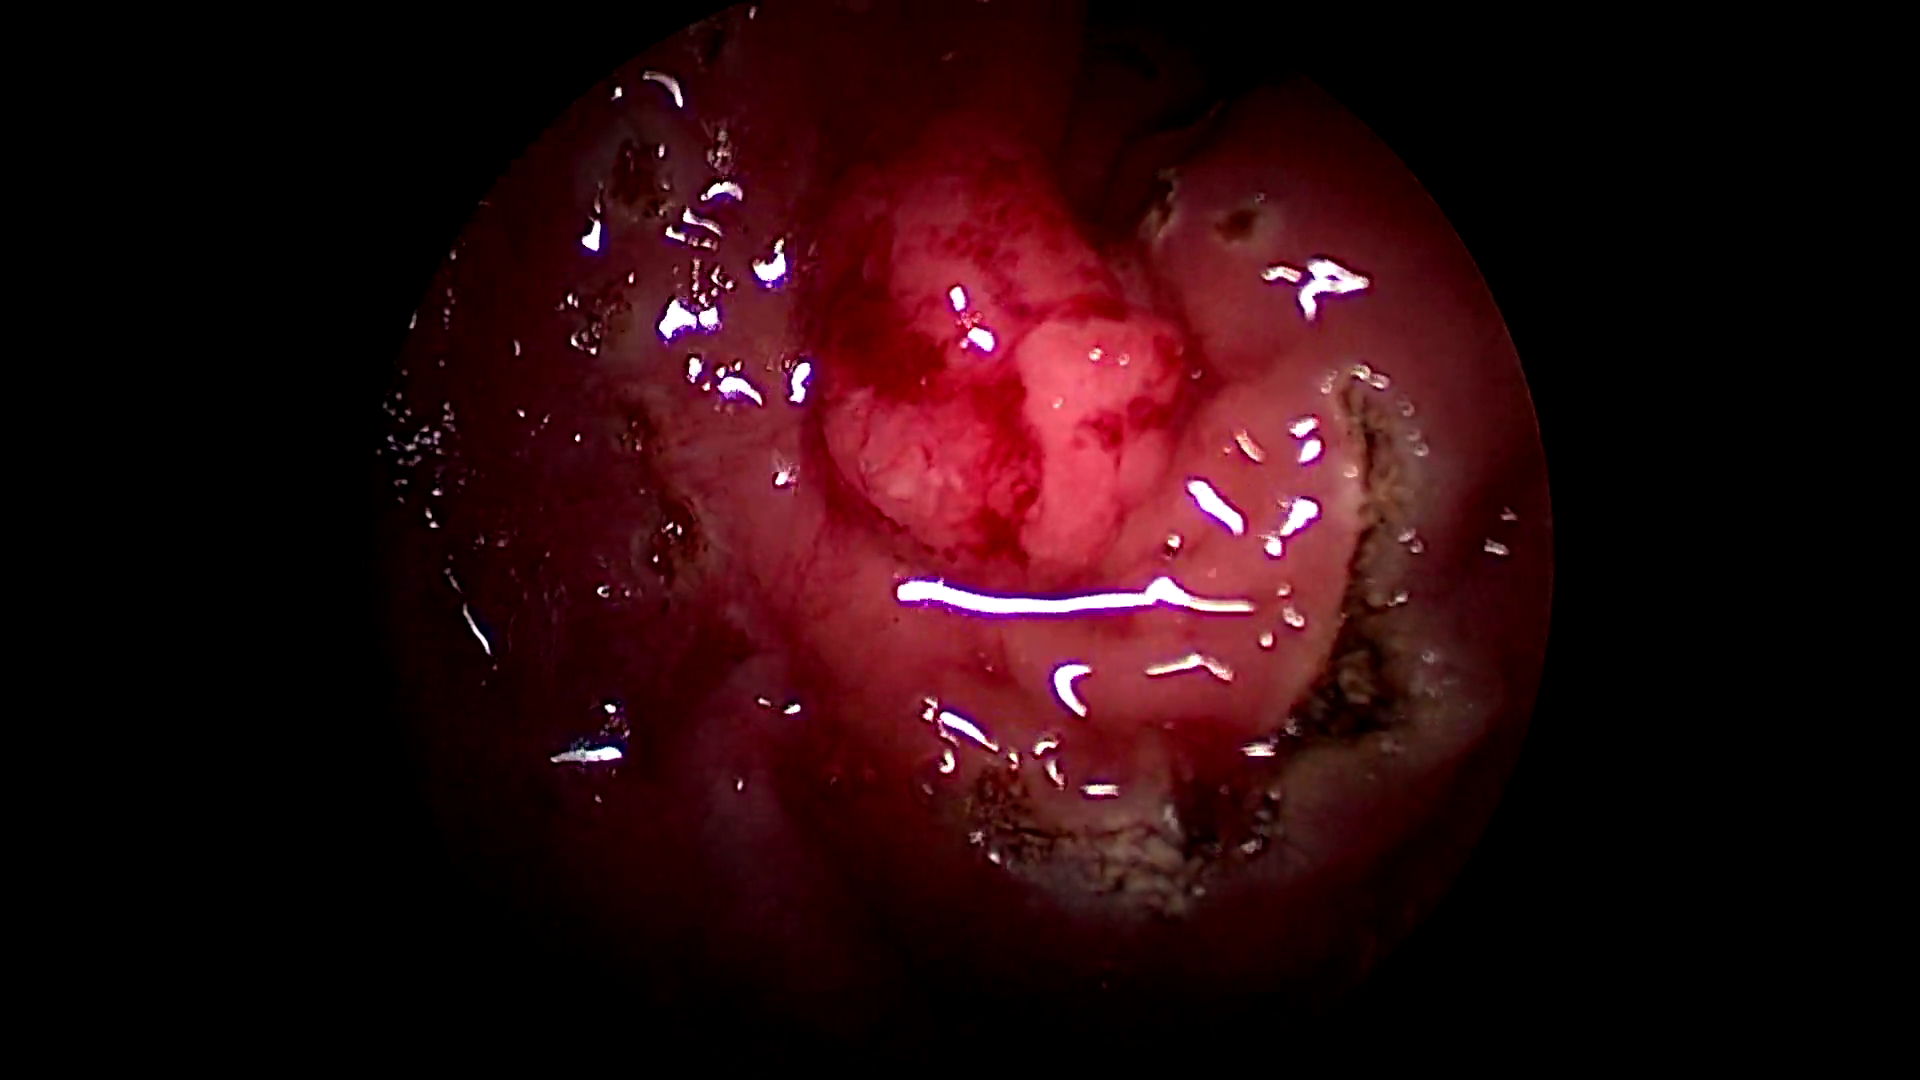

In [6]:
PILImage.create(im)

In [7]:
labels = get_image_files(MASKS_DIR)
labels

(#2596) [Path('dataset/masks/001708.png'),Path('dataset/masks/000050.png'),Path('dataset/masks/001381.png'),Path('dataset/masks/001547.png'),Path('dataset/masks/001578.png'),Path('dataset/masks/002206.png'),Path('dataset/masks/000660.png'),Path('dataset/masks/001871.png'),Path('dataset/masks/001552.png'),Path('dataset/masks/001749.png')...]

In [8]:
lbl = labels[2400]; lbl

Path('dataset/masks/000722.png')

In [9]:
msk = PILMask.create(lbl); msk
np.unique(msk)

array([ 0,  1,  2,  3, 16], dtype=uint8)

In [10]:
RectalCodes = (
    'Background',
    'RectalWall',
    'Lesion',
    'RectalWallDefect',
    'Lumen',
    'Rectoscope',
    'Retractor',
    'Diathermy',
    'Scissors',
    'Sucker',
    'Clipper',
    'Clip',
    'NeedleHolder',
    'Needle',
    'Snare',
    'Suture',
    'Landmark',
    'Reflection',
    'Blood',
    'Fluid',
    'Feces',
    'PoorVisibility',
    'OutOfBody'
)

Rectal_datablocks = (ImageBlock, MaskBlock(codes=RectalCodes))
print("Number of categories:", len(RectalCodes))
print("RectalCodes:", RectalCodes)


Number of categories: 23
RectalCodes: ('Background', 'RectalWall', 'Lesion', 'RectalWallDefect', 'Lumen', 'Rectoscope', 'Retractor', 'Diathermy', 'Scissors', 'Sucker', 'Clipper', 'Clip', 'NeedleHolder', 'Needle', 'Snare', 'Suture', 'Landmark', 'Reflection', 'Blood', 'Fluid', 'Feces', 'PoorVisibility', 'OutOfBody')


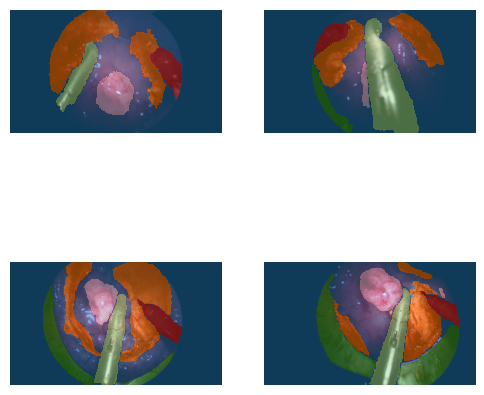

In [11]:
def get_y(x):
    return str(x).replace(str(IMAGES_DIR), str(MASKS_DIR))

datablock = DataBlock(
    blocks=(ImageBlock, MaskBlock(codes=RectalCodes)),
    get_items=get_image_files,
    get_y=get_y,
    item_tfms=Resize((224, 384)),
    batch_tfms=[*aug_transforms(), Normalize.from_stats(*imagenet_stats)]
)

dls = datablock.dataloaders(IMAGES_DIR, bs=4, num_workers=0)
dls.show_batch()

In [12]:
xb, yb = dls.one_batch()
xb.shape, yb.shape

(torch.Size([4, 3, 224, 384]), torch.Size([4, 224, 384]))

In [13]:
yb.unique()

TensorMask([ 0,  1,  2,  3,  5,  6,  7, 21, 22], device='cuda:0')

In [14]:
samples = dls.decode_batch(dls.one_batch())

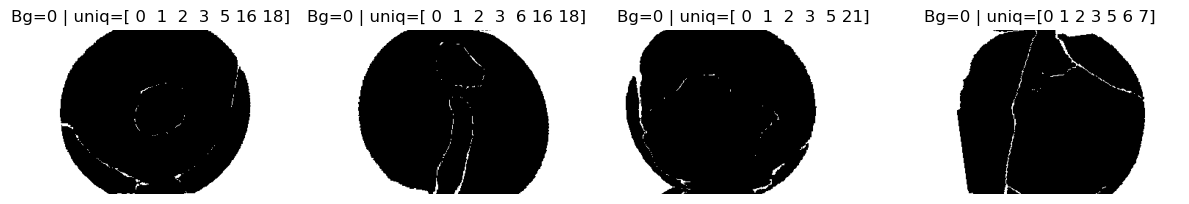

In [15]:
import numpy as np
import matplotlib.pyplot as plt

N = min(4, len(samples))
fig, axs = plt.subplots(1, N, figsize=(3*N, 3))

for i in range(N):
    x_i, y_i = samples[i]           # x_i: PILImage, y_i: PILMask
    mask = np.array(y_i)            # [H,W] integer class ids
    bg = (mask == 0).astype(np.uint8)

    axs[i].imshow(bg, cmap='gray')  # white=background, black=non-background
    axs[i].set_title(f'Bg=0 | uniq={np.unique(mask)}')
    axs[i].axis('off')

plt.tight_layout()
plt.show()

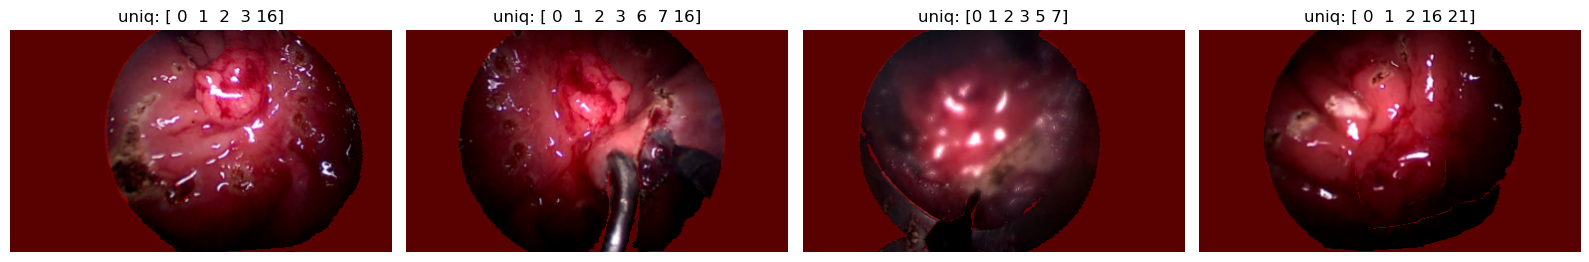

In [16]:
samples = dls.decode_batch(dls.one_batch())

import numpy as np
import matplotlib.pyplot as plt

N = min(4, len(samples))
plt.figure(figsize=(4*N, 4))

for i in range(N):
    x_i, y_i = samples[i]

    # ---- get image as HWC uint8 ----
    x = getattr(x_i, "tensor", x_i)          # fastai TensorImage or PIL
    if hasattr(x, "permute"):                # Tensor (CHW, float)
        img = x.permute(1, 2, 0).cpu().numpy()
        if img.max() <= 1.0: img = (img*255).clip(0,255).astype(np.uint8)
        else: img = img.astype(np.uint8)
    else:                                    # PILImage
        img = np.array(x_i).astype(np.uint8)

    # ---- mask as HW ----
    m  = np.array(y_i)
    bg = (m == 0)                            # background

    # ---- overlay background in red ----
    overlay = img.copy()                     # HWC
    overlay[bg] = [255, 0, 0]                # apply on spatial dims
    alpha = 0.35
    vis = (alpha*overlay + (1-alpha)*img).astype(np.uint8)

    ax = plt.subplot(1, N, i+1)
    ax.imshow(vis)
    ax.set_title(f"uniq: {np.unique(m)}")
    ax.axis('off')

plt.tight_layout(); plt.show()

In [17]:
len(dls.train_ds), len(dls.valid_ds)

(2077, 519)

In [18]:
num_classes = 23

model = smp.DeepLabV3Plus(
    encoder_name='efficientnet-b5',
    encoder_weights='imagenet',
    in_channels=3,
    classes=num_classes,
    activation=None
)

In [19]:
import sys, torch, fastai, fastcore
print("python:", sys.executable)
print("torch:", torch.__version__)
print("fastai:", fastai.__version__)
print("fastcore:", fastcore.__version__)
print("fastai path:", fastai.__file__)


python: /home/exsdatalab/miniconda3/envs/fastai/bin/python
torch: 2.8.0+cu128
fastai: 2.7.17
fastcore: 1.5.29
fastai path: /home/exsdatalab/miniconda3/envs/fastai/lib/python3.9/site-packages/fastai/__init__.py


In [20]:
learn = Learner(
    dls, 
    model, 
    loss_func=FocalLossFlat(axis=1), 
    metrics=[foreground_acc, DiceMulti(axis=1)],
    opt_func=ranger
).to_fp16()

In [21]:
import torch.serialization
from fastcore.foundation import L

torch.serialization.add_safe_globals([L])

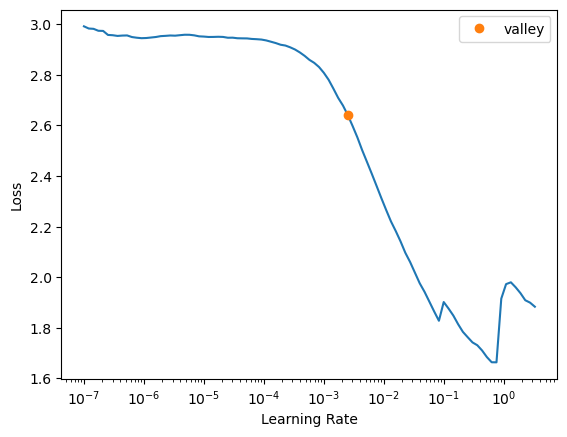

In [22]:
learn.to_fp32()      # TEMPORARY: disable fp16 ONLY for lr_find
learn.lr_find()     # run LR finder safely
learn.to_fp16()     # return to fp16 for training

In [ ]:
learn.fit_one_cycle(50, 1e-3)
learn.show_results(max_n=4, figsize=(6,12))

epoch,train_loss,valid_loss,foreground_acc,dice_multi,time
0,0.607779,0.443298,0.722278,0.478242,03:34
1,0.221806,0.163947,0.835288,0.589332,03:21
2,0.127168,0.097967,0.890245,0.674010,03:25
3,0.099962,0.083279,0.902258,0.709093,03:24
4,0.086851,0.068960,0.914968,0.767286,03:22
5,0.088435,0.082111,0.893665,0.749802,03:23
6,0.073944,0.064913,0.915456,0.778849,03:23
7,0.068383,0.063196,0.918285,0.771724,03:25
8,0.077361,0.063764,0.921651,0.777192,03:23
9,0.059955,0.061909,0.922707,0.781048,03:26


In [52]:
learn.unfreeze()
learn.fit_one_cycle(50, slice(1e-3/400, 1e-3/4))

epoch,train_loss,valid_loss,foreground_acc,dice_multi,time
0,0.157591,0.112320,0.880515,0.696133,02:58
1,0.159923,0.112090,0.881365,0.699602,03:00
2,0.152455,0.112187,0.881337,0.696193,03:00
3,0.151432,0.112601,0.881845,0.699584,03:00
4,0.160765,0.112149,0.881861,0.698952,03:01
5,0.167808,0.111984,0.881030,0.701688,03:01
6,0.161250,0.111165,0.881634,0.703800,02:57
7,0.150762,0.111188,0.882583,0.704221,02:59
8,0.152203,0.110186,0.882471,0.704216,03:01
9,0.161916,0.111060,0.882238,0.706712,03:02


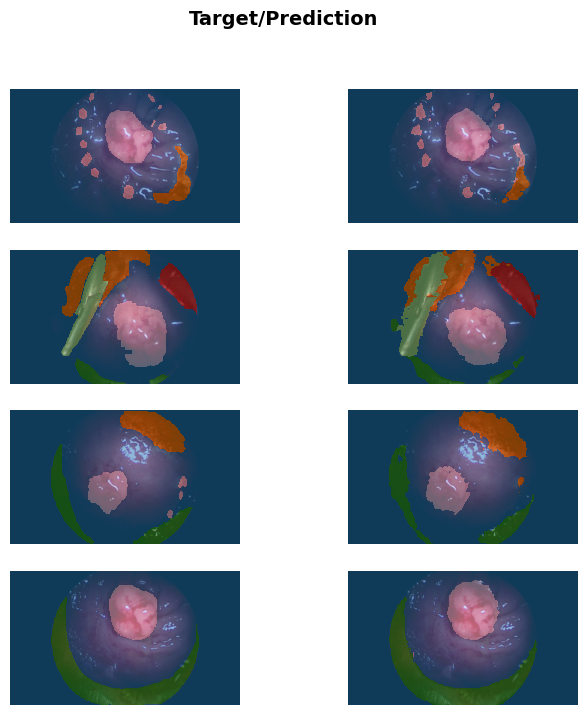

In [53]:
learn.show_results(max_n=5, figsize=(8,8))

In [60]:
import torch, pandas as pd

def per_class_metrics(model, dl, codes):
    model.eval()
    C = len(codes)
    eps = 1e-7

    TP = torch.zeros(C, dtype=torch.float64)
    FP = torch.zeros(C, dtype=torch.float64)
    FN = torch.zeros(C, dtype=torch.float64)
    TN = torch.zeros(C, dtype=torch.float64)

    with torch.no_grad():
        for xb, yb in dl:
            preds = model(xb).argmax(1)  # [B,H,W]

            # FORCE: plain tensors on CPU (not fastai subclasses)
            preds = preds.detach().cpu().clone().to(torch.int64)
            yb    = yb.detach().cpu().clone().to(torch.int64)

            for c in range(C):
                p = (preds == c).to(torch.bool)
                g = (yb == c).to(torch.bool)

                TP[c] += (p * g).sum().item()
                FP[c] += (p * (~g)).sum().item()
                FN[c] += ((~p) * g).sum().item()
                TN[c] += ((~p) * (~g)).sum().item()

    precision = TP / (TP + FP + eps)
    recall    = TP / (TP + FN + eps)
    f1        = 2 * precision * recall / (precision + recall + eps)
    acc       = (TP + TN) / (TP + TN + FP + FN + eps)

    return pd.DataFrame({
        "Class": codes,
        "Accuracy": acc.numpy(),
        "F1": f1.numpy(),
        "Precision": precision.numpy(),
        "Recall": recall.numpy(),
    })


In [65]:
from IPython.display import display

display(df_train)
display(df_valid)

display(df_train[df_train["Class"] != "Background"].mean(numeric_only=True))
display(df_valid[df_valid["Class"] != "Background"].mean(numeric_only=True))


,Class,Accuracy,F1,Precision,Recall
0,Background,0.976930,0.974246,0.983447,0.965215
1,RectalWall,0.947423,0.893615,0.892324,0.894910
2,Lesion,0.986483,0.865802,0.847132,0.885313
3,RectalWallDefect,0.976496,0.835114,0.816030,0.855111
4,Lumen,1.000000,0.000000,0.000000,0.000000
5,Rectoscope,0.986943,0.884722,0.855532,0.915974
6,Retractor,0.992434,0.872207,0.863127,0.881481
7,Diathermy,0.993161,0.823191,0.776483,0.875879
8,Scissors,1.000000,0.000000,0.000000,0.000000
9,Sucker,0.999980,0.000000,0.000000,0.000000


,Class,Accuracy,F1,Precision,Recall
0,Background,0.977446,0.975702,0.987402,0.964276
1,RectalWall,0.950371,0.892110,0.890803,0.893421
2,Lesion,0.987627,0.867450,0.849328,0.886363
3,RectalWallDefect,0.977879,0.834015,0.815049,0.853884
4,Lumen,1.000000,0.000000,0.000000,0.000000
5,Rectoscope,0.986797,0.885618,0.846249,0.928829
6,Retractor,0.992570,0.875165,0.865167,0.885397
7,Diathermy,0.993653,0.831838,0.779151,0.892168
8,Scissors,1.000000,0.000000,0.000000,0.000000
9,Sucker,1.000000,0.000000,0.000000,0.000000


Accuracy     0.994023
F1           0.358383
Precision    0.367530
Recall       0.355848
dtype: float64

Accuracy     0.994288
F1           0.356652
Precision    0.363688
Recall       0.355639
dtype: float64

In [68]:
learn.save("deeplabv3p_effb5_final")

Path('models/deeplabv3p_effb5_final.pth')

In [50]:
# --- ONE-CELL SAVE (saves everything to ./models) ---

import os, json, torch

# Ensure folder exists
os.makedirs('models', exist_ok=True)

# A) Save PyTorch model weights
torch.save(learn.model.state_dict(), 'models/deeplabv3_effb5_final.pth')

# B) Save the full FastAI Learner for quick reuse
learn.export('models/deeplabv3_effb5_final.pkl')

# C) Save class labels (robust detection)
classes = None

# Try to get class names from DataLoaders
if hasattr(learn.dls, 'vocab') and learn.dls.vocab is not None:
    classes = list(learn.dls.vocab)
elif hasattr(learn.dls, 'train_ds') and hasattr(learn.dls.train_ds, 'vocab') and learn.dls.train_ds.vocab is not None:
    classes = list(learn.dls.train_ds.vocab)
elif hasattr(learn.dls, 'dataset') and hasattr(learn.dls.dataset, 'codes') and learn.dls.dataset.codes is not None:
    classes = list(learn.dls.dataset.codes)

# Fallback: infer number of classes from SMP model head
if classes is None:
    head = getattr(learn.model, 'segmentation_head', None)
    out_ch = getattr(head, 'out_channels', None)
    if out_ch is None and hasattr(head, '0') and hasattr(head[0], 'out_channels'):
        out_ch = head[0].out_channels
    if out_ch is None:
        raise RuntimeError("Could not determine number of classes; please set `classes` manually.")
    classes = [f"class_{i}" for i in range(int(out_ch))]

# Save to JSON
with open('models/deeplabv3_effb5_classes.json', 'w') as f:
    json.dump(classes, f, indent=2)

print(f"✅ Saved model files to 'models/' folder:\n"
      f" - deeplabv3_effb5_final.pth\n"
      f" - deeplabv3_effb5_final.pkl\n"
      f" - deeplabv3_effb5_classes.json ({len(classes)} classes)")


✅ Saved model files to 'models/' folder:
 - deeplabv3_effb5_final.pth
 - deeplabv3_effb5_final.pkl
 - deeplabv3_effb5_classes.json (23 classes)
